---
title: "Big Data Bowl 2027: Getting Started with Tracking Data & EDA"
subtitle: "From the Combine to Sundays, in Python"
author: "UWAGGS & UTSPAN"
date: 2026-11-05
format:
  revealjs:
    scrollable: true        # long code/output slides scroll instead of overflowing
    smaller: true
    code-overflow: wrap
    slide-number: true
    embed-resources: true   # one self-contained .html (figures inlined)
    auto-stretch: false     # keeps GIFs/images from collapsing on scrollable slides
    include-after-body: templates/title-logos.html   # logos on the opening slide
    echo: true              # show code...
    code-fold: true         # ...folded behind a toggle
    code-summary: "Show code"
---


## Today

1. 2027 Big Data Bowl Competition Theme
2. Introductory look at the data given by the BDB
3. **Cleaning:** rebuilding the [ngscleanR](https://github.com/guga31bb/ngscleanR) helpers for the 2027 data
4. **Basic Visualizations:** plays, routes and Combine drills


This notebook is done in **Python** (pandas + matplotlib) version. The R (tidyverse) version of the same code is in `bdb_tutorial.R`.

Builds on Ron Yurko’s [CMSAC 2022 Big Data Bowl workshop](https://www.stat.cmu.edu/cmsac/conference/2022/workshop/slides.html) and Ben Baldwin’s [ngscleanR](https://github.com/guga31bb/ngscleanR).

## What is the Big Data Bowl?

- An annual NFL analytics competition on [Kaggle](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027), built on Next Gen Stats player tracking
- **2027 theme: Combine → NFL performance.** Analyze prospect movement from combine drills, and how it translates to performance in the NFL. 
- Two tracks: **Open** and **University** (undergraduates only)
- Submission: a Kaggle Writeup of **≤ 2,000 words** with **< 10 figures/tables**, plus a public notebook
- Judging: Football 30% · Data Science 30% · Writeup 20% · Data Visualization 20%
- Entries **must use the tracking data**
- **Due Jan 6, 2027** (11:59 PM UTC). Finalists present at the 2027 Scouting Combine (in Indianapolis) + Prizes. 

## The data

* High-frequency tracking data of players during drills 
* Standardized physical test results 
* In-season NFL performance of the prospects drafted/signed between 2023 and 2025

510 rookies drafted or signed in 2023–2025, tracked at the Combine **and** in NFL games from 2023 to 2025.



| File | Rows | Columns | Granularity (row per) | Key |
|---|---|---|---|---|
| `players.csv` | 510 | 10 | player | `nfl_id` |
| `combine_results.csv` | 510 | 18 | player | `nfl_id` |
| `player_career_successes.csv` | 510 | 9 | player | `nfl_id` |
| `combine_tracking.csv` | 463,189 | 14 | entity × drill attempt × frame | `event_id`, `nfl_id`, `entity_type`, `time` |
| `games.csv` | 1,002 | 7 | game | `game_id` |
| `player_play.csv` | 314,197 | 64 | player × play | `game_id`, `play_id`, `nfl_id` |
| `game_tracking_2023.csv` | 3,665,443 | 12 | player × play × frame | `game_id`, `play_id`, `nfl_id`, `time` |
| `game_tracking_2024.csv` | 7,827,944 | 12 | player × play × frame | ^ |
| `game_tracking_2025.csv` | 11,160,903 | 12 | player × play × frame | ^ |

nfl_id = player's unique ID across all tables

entity = player or ball

event_id = unique ID to link all tracking frames of a single drill attempt

## How the files join
```
 COMBINE                                    NFL GAMES

 combine_tracking                           games
 (drill × frame)                            (season_type)
        │                                         │
        │ nfl_id                                  │ game_id
        ▼                                         ▼
 players            ─────── nfl_id ──────▶  player_play
 combine_results                            (player × play)
 career_successes                                 │
                                                  │ game_id, play_id, nfl_id
                                                  ▼
                                            game_tracking
                                            (player × play × frame)
```
`nfl_id` is the bridge: **Combine** on the left, **Sundays** on the right.

## How 2027 differs from past BDBs

> - **Only the 510 rookies are tracked in games.** Most plays have 1–2 tracked players (at most 11), and there’s **no ball**.
> - Game tracking has **no `frame_id`, team or jersey**. Build the frame from `time` and join `player_play` for everything else.
> - `play_direction`, line of scrimmage, `route_ran`, coverage and separation all live in **`player_play.csv`**.
> - `games.csv` mixes PRE / REG / POST. Can drop plays with `play_nullified_by_penalty == "Y"` as well.
> - Combine tracking: **drill names drift** across years, coordinates are drill-local, and clips begin in motion.


# Part 1 · Load data

## Packages

In [74]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pv
import pyarrow.dataset as ds
from matplotlib.animation import FuncAnimation, PillowWriter
import plotly.io as pio
pio.renderers.default = "vscode+notebook_connected"   


pd.set_option("display.width", 90, "display.max_columns", 12)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
SIDE_COLS = {"Offense": "#0072B2", "Defense": "#D55E00"}   # Okabe-Ito

## Find the data

On Kaggle, generate an API token. It will give you instructions on how to save the token, either by setting the environment variable 
```
export KAGGLE_USERNAME={your_username}
export KAGGLE_API_TOKEN={your_key}
```
Or saving it to ~/.kaggle/access_token (make a folder for it within your root directory)
```
mkdir -p ~/.kaggle && echo {your_key} > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token
```

Then you can download the data for the competition (can also download directly from the website, but this will probably be smoother with your workflow). Once downloaded once, no need to rerun (data is large)

In [75]:
# # from kaggle, download the bdb2027 data and create a folder for it 
# !kaggle competitions download -c nfl-big-data-bowl-2027 -p nfl-big-data-bowl-2027
# # unzip the data into the created folder
# !unzip -j nfl-big-data-bowl-2027/nfl-big-data-bowl-2027.zip -d nfl-big-data-bowl-2027

In [76]:
# Boring setup code not that important for tutorial
# Assuming you are in your Big Data Bowl work folder, this will find a "data" folder. 
# In that data folder, it will look for the BDB 2027 data.
# If you have your own copy of the data, you can set the BDB_DIR environment variable to point to it.
# It then creates a cache folder for the parquet files and a figs folder for figures (for the public Kaggle notebook)
def find_bdb_dir():
    '''
    Return the first directory that exists, checking in order:
    1. the BDB_DIR environment variable, if set
    2. the Kaggle notebook input path (/kaggle/input/nfl-big-data-bowl-2027)
    3. ../../nfl-big-data-bowl-2027 (two levels up)
    4. ./nfl-big-data-bowl-2027 (next to the notebook)    
    '''
    candidates = [os.environ.get("BDB_DIR", ""),               # your own override
                  "/kaggle/input/nfl-big-data-bowl-2027",      # Kaggle notebook
                  "../../nfl-big-data-bowl-2027",              # this repo
                  "nfl-big-data-bowl-2027"]
    for path in candidates:
        if path and os.path.isdir(path):
            return path
    raise FileNotFoundError("Can't find the BDB 2027 data: set BDB_DIR")

bdb_dir = find_bdb_dir()
cache_dir = os.environ.get("BDB_CACHE", "bdb_cache")   # Kaggle input is read-only
os.makedirs(cache_dir, exist_ok=True)
os.makedirs("figs", exist_ok=True)

## Looking at the some tables

In [77]:
players = pd.read_csv(f"{bdb_dir}/players.csv") # metadata of the 510 college prospects
combine = pd.read_csv(f"{bdb_dir}/combine_results.csv") # measurements, physical testing splits, and NGS draft grades from the combine
games   = pd.read_csv(f"{bdb_dir}/games.csv") # schedule/team metadata for every game in the 2023/4/5 seasons (reg + playoffs)
plays   = pd.read_csv(f"{bdb_dir}/player_play.csv", low_memory=False) # play-by-play tracking data for every snap involving a draft prospect, across 2023/4/5 seasons

As mentioned before, ```players``` is just the 510 prospects metadata (e.g their actual names)


In [78]:
players.sort_values(by='draft_overall_pick').head(5)

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
337,58206,Will Campbell,2025,T,2004-01-06,Louisiana State,Southeastern Conference,1.0,4.0,4.0
160,57126,Joe Alt,2024,T,2003-02-28,Notre Dame,Independent,1.0,5.0,5.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
338,58209,Armand Membou,2025,T,2004-03-27,Missouri,Southeastern Conference,1.0,7.0,7.0


## Looking at the some tables

From ```combine```, we have each player's testing at the combine. This is a sparse dataset, why is that? 

In [79]:
combine.head(5)

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,...,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,...,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,...,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,...,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,...,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,...,6.98,4.15,14.0,65,65.0,64.0


## Looking at the some tables

Note that ```games``` includes regular season (REG), preseason (PRE), and post-season (POST). One could argue that you should only look at regular season games + playoffs, thats a design choice.

In [80]:
print(f"Preseason games: {len(games.loc[games.season_type == 'PRE'])}, Regular season games: {len(games.loc[games.season_type == 'REG'])}, Postseason games: {len(games.loc[games.season_type == 'POST'])}")

Preseason games: 147, Regular season games: 816, Postseason games: 39


Another design choice is that you can argue plays with penalties aren't valid data to evaluate a player's performance, because they are called back anyways.

In [81]:
# Exclude plays that were nullified by penalties.
reg_plays = plays[(plays.play_nullified_by_penalty == "N")]
reg_game_ids = reg_plays.game_id.unique()

## Example of looking at particular player's performance
For an intuitive exploration of how Combine performance influences draft grade/perception

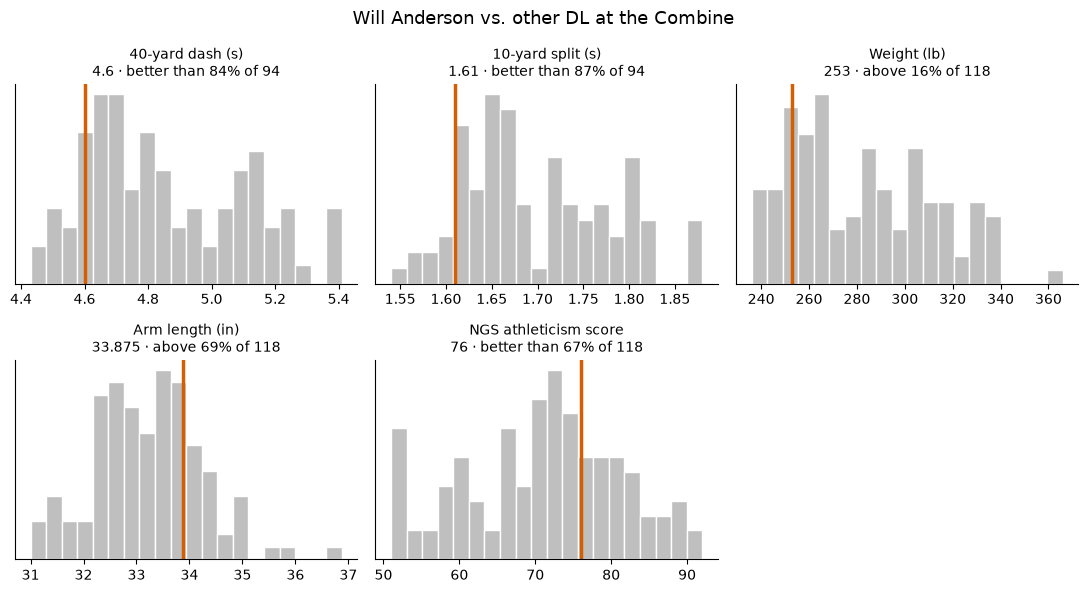

In [82]:
combine_w_names = players[['nfl_id', 'display_name']].merge(combine, on='nfl_id', how='right')

# column: (label, how to read it) - "low" = lower is better, "high" = higher is better,
COMBINE_TESTS = {"forty":         ("40-yard dash (s)", "low"),
                 "ten_yd_split":  ("10-yard split (s)", "low"),
                 "vertical":      ("Vertical (in)", "high"),
                 "broad_jump":    ("Broad jump (in)", "high"),
                 "three_cone":    ("3-cone (s)", "low"),
                 "short_shuttle": ("Short shuttle (s)", "low"),
                 "bench_reps":    ("Bench (reps)", "high"),
                 "combine_weight": ("Weight (lb)", "size"),
                 "arm_length":    ("Arm length (in)", "size"),
                 "ngs_athleticism_score": ("NGS athleticism score", "high")}

def plot_player_vs_position(name, df=combine_w_names, tests=COMBINE_TESTS):
    player = df.loc[df.display_name == name].iloc[0]
    peers = df[df.combine_position == player.combine_position]
    done = [col for col in tests if pd.notna(player[col])]   # skip tests he didn't do

    ncols = 3
    nrows = int(np.ceil(len(done) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3 * nrows), squeeze=False)
    for ax, col in zip(axes.flat, done):
        label, kind = tests[col]
        values = peers[col].dropna()
        if kind == "low":
            note = f"better than {(values > player[col]).mean():.0%}"
        elif kind == "high":
            note = f"better than {(values < player[col]).mean():.0%}"
        else:
            note = f"above {(values < player[col]).mean():.0%}"
        ax.hist(values, bins=20, color="0.75", edgecolor="white")
        ax.axvline(player[col], color="#D55E00", lw=2.5)
        ax.set_title(f"{label}\n{player[col]:g} · {note} of {len(values)}", fontsize=10)
        ax.set_yticks([])
    for ax in axes.flat[len(done):]:
        ax.axis("off")
    fig.suptitle(f"{name} vs. other {player.combine_position} at the Combine", fontsize=13)
    fig.tight_layout()
    return fig

plot_player_vs_position("Will Anderson")
plt.show()


## Tracking datasets

### Tracking: convert to Parquet once

2 GB of CSV is slow to re-read. Convert it once to **Parquet**, a compressed, columnar format that both languages read, then query it **lazily**.

In [ ]:
tracking_dir = f"{cache_dir}/game_tracking"
# The CSV files are large, so we convert them to Parquet for faster reading
csv_format = ds.CsvFileFormat(convert_options=pv.ConvertOptions(
    strings_can_be_null=True,                 # read "NA" as missing
    column_types={"event": pa.string()}))

# If the Parquet files don't exist yet, convert the CSVs to Parquet. This takes
if not os.path.isdir(tracking_dir):           # a minute or two, once
    for yr in [2023, 2024, 2025]:
        src = ds.dataset(f"{bdb_dir}/game_tracking_{yr}.csv", format=csv_format)
        ds.write_dataset(src, f"{tracking_dir}/season={yr}", format="parquet")

# Now we can read the Parquet files as a single dataset, tracking, and count the number of rows for each season. 
# tracking is a pyarrow dataset object, which allows us to query the data without loading it all into memory. 
# cons are its less familiar than pandas, you have to know what you want and then convert to pandas
# but that just means you have to be more explicit with what you want, and on what data. It is WAY quicker
tracking = ds.dataset(tracking_dir, format="parquet", partitioning="hive")
print({yr: tracking.count_rows(filter=ds.field("season") == yr)
       for yr in [2023, 2024, 2025]})


{2023: 3665443, 2024: 7827944, 2025: 11160903}


## Orientation

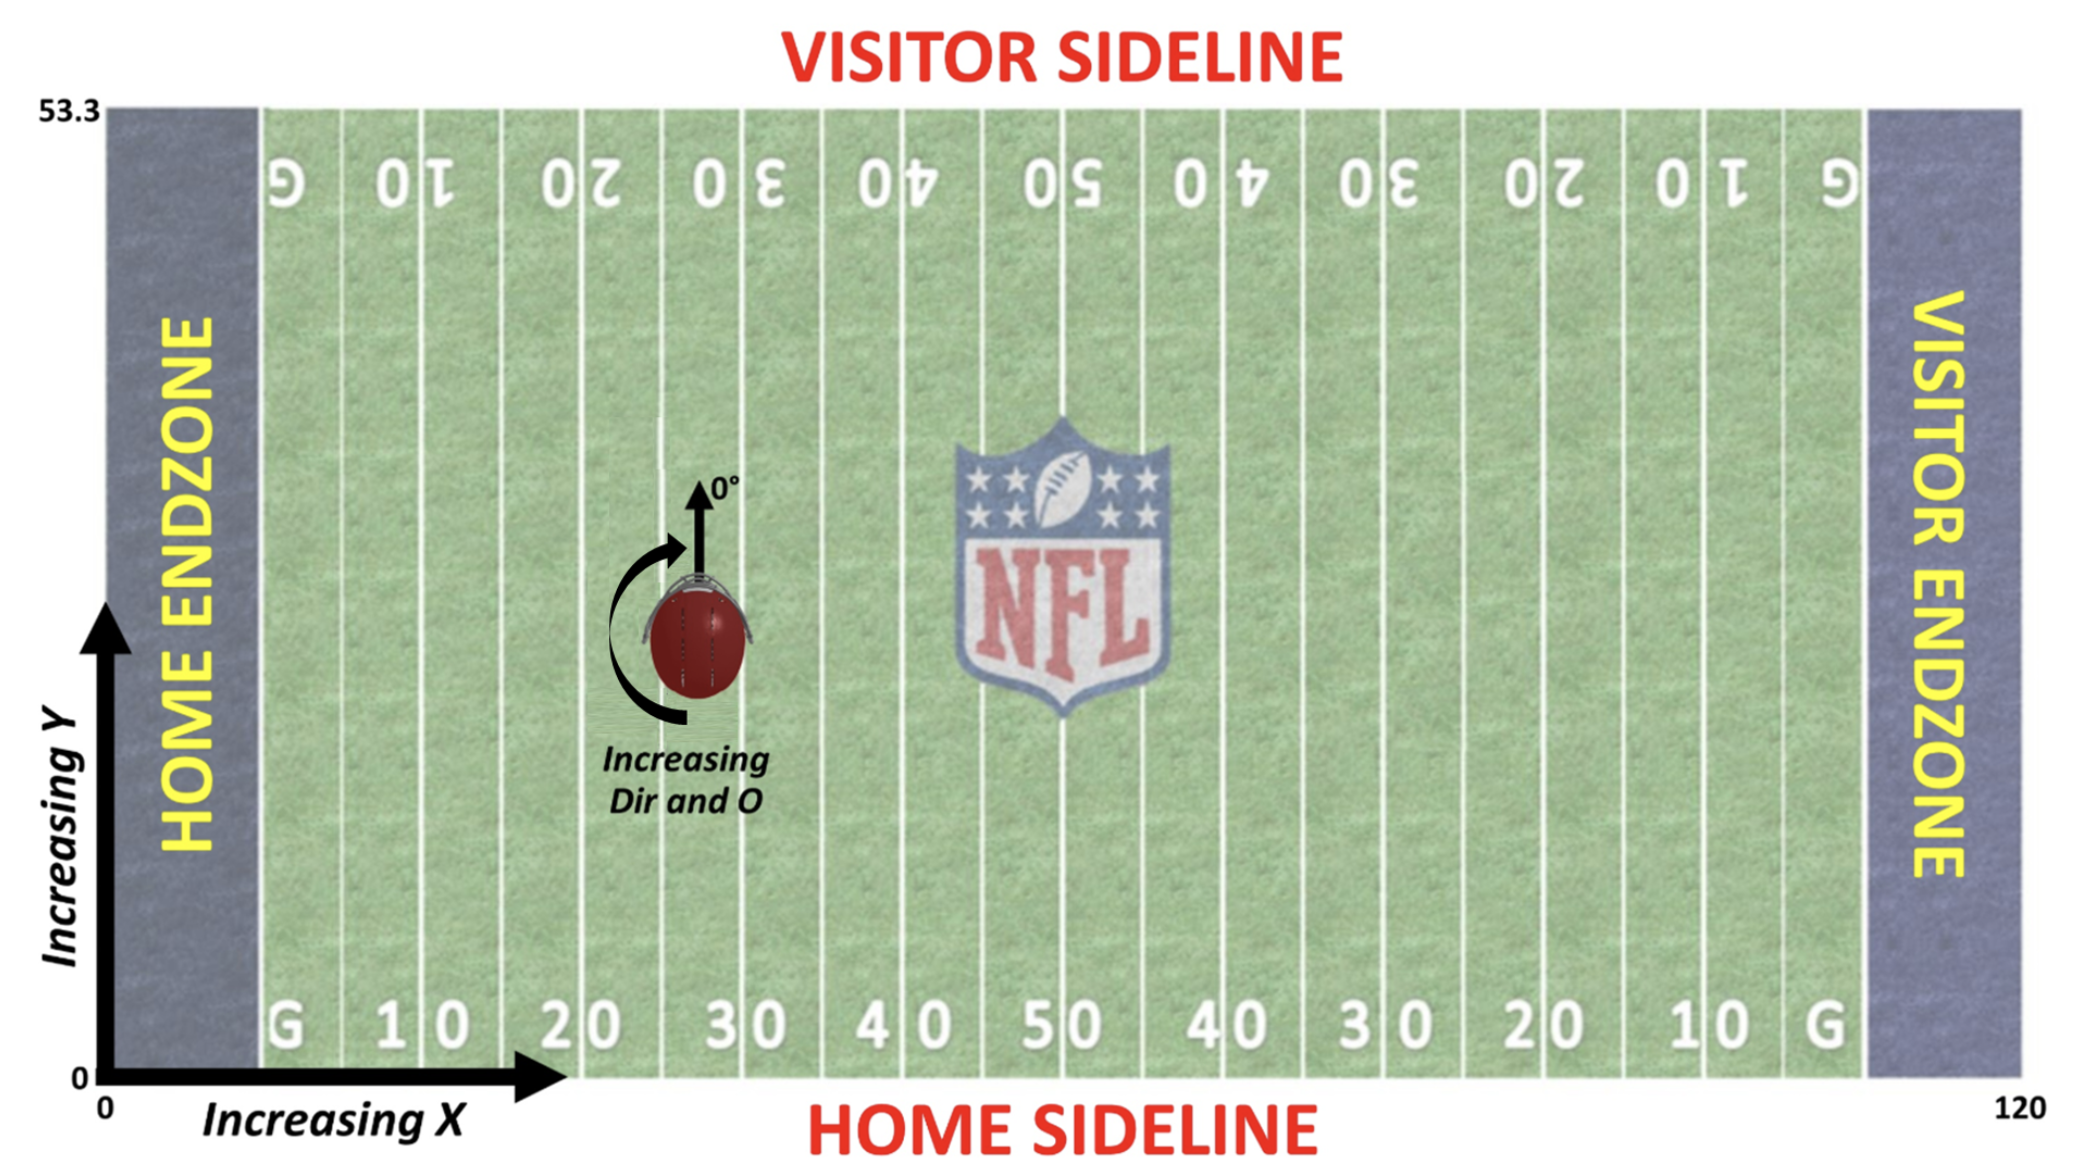

## Pull one play

A Week 18 2025 play (HOU vs IND) with **11** tracked rookies, a rare full-ish picture.

In [84]:
ex_game, ex_play = 2026010405, 4313

ex_raw = tracking.to_table(
    filter=(ds.field("game_id") == ex_game) & (ds.field("play_id") == ex_play)
).to_pandas()          # only now does data enter memory

So in this play, Davis Mills completed a pass to Jaylin Noel, who gained 13 yards to the IND 28, and was tackled by Camryn Bynum and Zaire Franklin (names in brackets).

In [85]:
print(reg_plays.query("game_id == @ex_game and play_id == @ex_play") # find the play desc for the example play from our plays dataset 
      .play_description.iloc[0])
ex_raw[["nfl_id", "time", 
              "x", "y", 
              "s", "a", "o", "dir", 
              "event"]]
# notice how event is missing for most rows - only appears at ball_snap, pass_forward, pass_arrived, tackle, touchdown, first_contact, out_of_bounds
# else, null (e.g presnap)

(1:48) (Shotgun) D.Mills pass short middle to J.Noel to IND 28 for 13 yards (C.Bynum; Z.Franklin).


,nfl_id,time,x,y,s,a,o,dir,event
0,57180,2026-01-04 21:05:40.900,52.51,26.48,0.00,0.00,264.00,57.28,NaN
1,57180,2026-01-04 21:05:41.000,52.51,26.48,0.00,0.00,264.00,57.46,NaN
2,57180,2026-01-04 21:05:41.100,52.51,26.48,0.00,0.00,264.00,66.09,NaN
3,57180,2026-01-04 21:05:41.200,52.51,26.48,0.00,0.00,264.73,67.35,NaN
4,57180,2026-01-04 21:05:41.300,52.51,26.48,0.00,0.00,264.73,70.84,NaN
...,...,...,...,...,...,...,...,...,...
732,57244,2026-01-04 21:05:47.100,40.99,9.89,1.31,1.79,337.42,284.24,NaN
733,57244,2026-01-04 21:05:47.200,40.87,9.92,1.16,1.78,345.51,290.50,NaN
734,57244,2026-01-04 21:05:47.300,40.77,9.96,1.00,1.76,351.78,297.77,NaN
735,57244,2026-01-04 21:05:47.400,40.70,10.02,0.90,1.83,358.00,311.09,NaN


# Part 2 · Cleaning the tracking data

## Anatomy of a tracking row

| Column | Meaning |
|---|---|
| `x`, `y` | position in yards (end zones are 0–10 and 110–120) |
| `s` | speed (yd/s) |
| `a` | acceleration (yd/s²) |
| `dis` | distance since the last frame (yd) |
| `dir` | direction of **motion** (°) |
| `o` | direction the player **faces** (°) |
| `event` | `ball_snap`, `pass_forward`, `tackle`, … |


## Frame ids from `time`

Frames are 0.1 s apart, so number them from the first timestamp on each play.

In [86]:
def add_frame_id(trk):
    '''
    start the frame count at the play's earliest timestamp (from time col), then +1 per 0.1 s elapsed bc 10hz
    '''
    t0 = trk.groupby(["game_id", "play_id"]).time.transform("min")
    out = trk.copy()
    out["frame_id"] = 1 + ((out.time - t0).dt.total_seconds() * 10).round().astype(int)
    return out

# get only the frames where an event is labelled i.e key frames of the play
print(add_frame_id(ex_raw).dropna(subset=["event"])[["frame_id", "event"]]
      .drop_duplicates().to_string(index=False))

 frame_id               event
       10           ball_snap
       29        pass_forward
       35        pass_arrived
       41 pass_outcome_caught
       50       first_contact
       56              tackle


## `standardize_tracking()`: offense always moves right

The ngscleanR `clean_and_rotate()` step. Flip plays such that the offense always moves towards increasing x (i.e left to right). Why would we want to do this? 
<details>
<summary><b>Why standardize?</b></summary>

We don't really care whether a play runs left to right or right to left. Standardizing lines up features across plays. For example, to overlay a player's route tree, we want every route to stem in the same direction.

</details>



In [87]:
def standardize_tracking(trk, plays):
    dirs = (plays[["game_id", "play_id", "play_direction"]]
            .dropna().drop_duplicates())
    out = trk.merge(dirs, on=["game_id", "play_id"])
    flip = out.play_direction == "left"
    out.loc[flip, "x"] = 120 - out.loc[flip, "x"]
    out.loc[flip, "y"] = 160 / 3 - out.loc[flip, "y"]
    for col in ["dir", "o"]:
        out.loc[flip, col] = (out.loc[flip, col] + 180) % 360
    rad = np.deg2rad(out.dir)
    out["dir_x"], out["dir_y"] = np.sin(rad), np.cos(rad)       # unit vector
    out["s_x"], out["s_y"] = out.s * out.dir_x, out.s * out.dir_y   # velocity
    return out

## Before and after

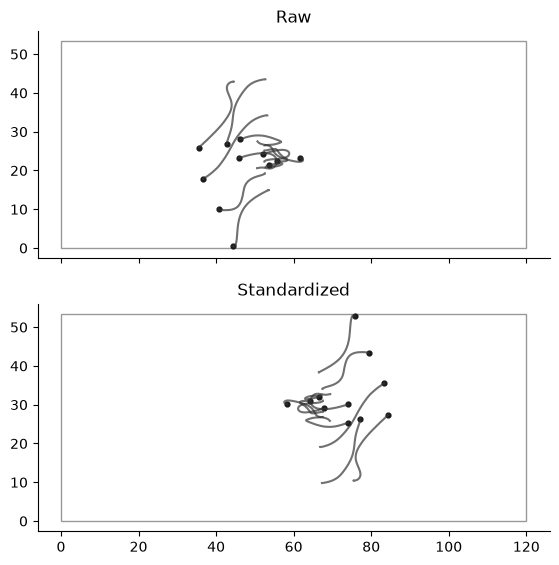

In [88]:
ex_std = standardize_tracking(add_frame_id(ex_raw), reg_plays)

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
for ax, (label, df) in zip(axes, [("Raw", ex_raw), ("Standardized", ex_std)]):
    ax.add_patch(plt.Rectangle((0, 0), 120, 160 / 3, fill=False, ec="0.6"))
    for _, path in df.sort_values("time").groupby("nfl_id"):
        ax.plot(path.x, path.y, color="0.2", alpha=0.7)
        ax.scatter(path.x.iloc[-1], path.y.iloc[-1], color="0.1", s=12)
    ax.set_title(label)
    ax.set_aspect("equal")
plt.show()

## `add_los()`: where is the line of scrimmage?

Can help to know where people are lined up, e.g how far back from the official LOS. (for example, say you find that a certain prospect has a certain characteristic, and in the NFL they are used exclusively in press i.e we notice in their plays, they are often much closer to the LOS)

In [89]:
def add_los(trk, plays):
    los = (plays[["game_id", "play_id", "possession_team", "yardline_side",
                  "yardline_number"]].drop_duplicates(["game_id", "play_id"]))
    own_half = los.yardline_side == los.possession_team
    los["los_x"] = np.where(los.yardline_side.isna(), 60,               # midfield
                   np.where(own_half, 10 + los.yardline_number,         # own half
                                      110 - los.yardline_number))       # their half
    out = trk.merge(los[["game_id", "play_id", "los_x"]],
                    on=["game_id", "play_id"], how="left")
    out["x_from_los"] = out.x - out.los_x
    return out

roles = reg_plays[["game_id", "play_id", "nfl_id", "team_abbr",
                   "possession_team", "lined_up_position"]]
ex_play_df = add_los(ex_std, reg_plays).merge(roles, on=["game_id", "play_id", "nfl_id"])
ex_play_df["side"] = np.where(ex_play_df.team_abbr == ex_play_df.possession_team,
                              "Offense", "Defense")

print(ex_play_df.query("event == 'ball_snap'")
      [["side", "lined_up_position", "x_from_los"]].sort_values("x_from_los"))

        side lined_up_position  x_from_los
478  Offense                WR       -2.46
210  Offense           SLOT_WR       -2.20
545  Offense                 T       -1.79
344  Offense                WR       -1.71
9    Offense                 T       -1.63
612  Offense                 G       -1.57
679  Offense                TE       -1.55
277  Offense                 G       -1.53
411  Defense              EDGE        0.11
76   Defense              EDGE        0.35
143  Defense                CB        6.50


## `trim_plays()`: cutting out frames 

The ngscleanR `cut_plays()` step. Keep the frames from the snap to the throw (or sack, handoff, …). (note that you can manipulate this to what you want, for example you want purely presnap frames, or post-handoff snaps, etc.)

In [90]:
END_EVENTS = ["pass_forward", "qb_sack", "qb_strip_sack",
              "handoff", "run", "qb_kneel", "qb_spike"]

def trim_plays(trk, start_events=("ball_snap",), end_events=END_EVENTS,
               frames_after_end=0):
    keys = ["game_id", "play_id"]
    ev = trk.dropna(subset=["event"])[keys + ["frame_id", "event"]]
    snap = (ev[ev.event.isin(start_events)].groupby(keys).frame_id.min()
            .rename("snap_frame").reset_index())
    ev = ev.merge(snap, on=keys)
    end = (ev[ev.event.isin(end_events) & (ev.frame_id > ev.snap_frame)]
           .groupby(keys).frame_id.min().rename("end_frame").reset_index())
    out = trk.merge(snap, on=keys).merge(end, on=keys)
    out = out[out.frame_id.between(out.snap_frame,
                                   out.end_frame + frames_after_end)].copy()
    out["frames_since_snap"] = out.frame_id - out.snap_frame
    return out

print(trim_plays(ex_play_df).groupby("side").size())

side
Defense     60
Offense    160
dtype: int64


# Part 3 · Visualization

Here is probably one of the most important parts of the project

## Making a field

In [91]:
def draw_field(ax, xlim=(0, 120)):
    ax.add_patch(plt.Rectangle((0, 0), 120, 160 / 3, color="#eef3ea", zorder=0))
    for x0 in (0, 110):
        ax.add_patch(plt.Rectangle((x0, 0), 10, 160 / 3, color="0.85", zorder=0))
    ax.vlines(range(10, 111, 5), 0, 160 / 3, color="0.7", lw=0.8, zorder=1)
    ticks = [x for x in range(11, 110) if x % 5]
    for hash_y in (23.36667, 29.96667):
        ax.vlines(ticks, hash_y - 0.4, hash_y + 0.4, color="0.7", lw=0.6, zorder=1)
    for x, lab in zip(range(20, 101, 10), [10, 20, 30, 40, 50, 40, 30, 20, 10]):
        ax.text(x, 5, str(lab), ha="center", va="center", color="0.5", fontsize=10,
                clip_on=True)
    ax.add_patch(plt.Rectangle((0, 0), 120, 160 / 3, fill=False, ec="0.4", zorder=1))
    ax.set_xlim(*xlim)
    ax.set_ylim(0, 160 / 3)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax

def play_xlim(x, min_width=60):
    """Zoom to the action, but show at least `min_width` yards of field."""
    half = max((x.max() - x.min()) / 2 + 5, min_width / 2)
    mid = (x.max() + x.min()) / 2
    return (mid - half, mid + half)

## `plot_play()`: one frame, with trails

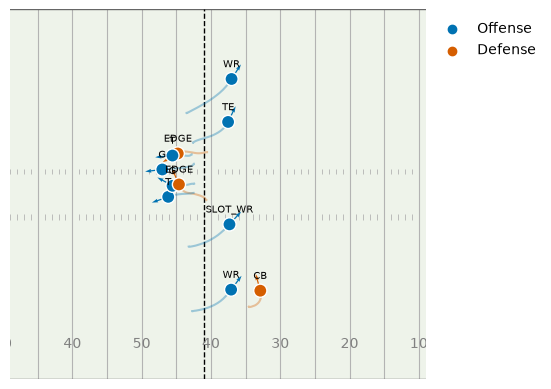

In [92]:
def plot_play(play_df, frame=None, arrow_len=2.5, ax=None):
    play_df = play_df.sort_values("frame_id")
    frame = play_df.frame_id.max() if frame is None else frame
    ax = ax or plt.subplots(figsize=(10, 4.8))[1]
    draw_field(ax, xlim=play_xlim(play_df.x))
    ax.axvline(play_df.los_x.iloc[0], color="k", ls="--", lw=1)
    for (_, side), path in play_df[play_df.frame_id <= frame].groupby(["nfl_id", "side"]):
        ax.plot(path.x, path.y, color=SIDE_COLS[side], alpha=0.35)
    now = play_df[play_df.frame_id == frame]
    cols = now.side.map(SIDE_COLS).tolist()
    ax.quiver(now.x, now.y, arrow_len * now.dir_x, arrow_len * now.dir_y, color=cols,
              angles="xy", scale_units="xy", scale=1, width=0.003)
    ax.scatter(now.x, now.y, c=cols, s=90, edgecolor="white", zorder=3)
    for _, p in now.iterrows():
        ax.text(p.x, p.y + 1.7, p.lined_up_position, ha="center", fontsize=7)
    for side, col in SIDE_COLS.items():
        ax.scatter([], [], c=col, label=side)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    return ax

throw_frame = ex_play_df.loc[ex_play_df.event == "pass_forward", "frame_id"].iloc[0]
plot_play(ex_play_df, frame=throw_frame)
plt.show()

## Animate the play

Plenty of different ways to animate. Recommended to use animations, for example, bringing up specific plays to illustrate your point

In [93]:
play = ex_play_df.sort_values("frame_id")
fig, ax = plt.subplots(figsize=(9, 4.2))
draw_field(ax, xlim=play_xlim(play.x))
ax.axvline(play.los_x.iloc[0], color="k", ls="--", lw=1)
dots = ax.scatter([], [], s=110, edgecolor="white", zorder=3)

def update(frame):
    now = play[play.frame_id == frame]
    dots.set_offsets(now[["x", "y"]].to_numpy())
    dots.set_facecolor(now.side.map(SIDE_COLS).tolist())
    ax.set_title(f"Frame {frame}")
    return (dots,)

FuncAnimation(fig, update, frames=play.frame_id.unique()).save(
    "figs/play_py.gif", writer=PillowWriter(fps=10))
plt.close(fig)

![](figs/play_py.gif)

## Alternative: interactive Plotly animation

Adapted from our BDB 2025 `visualization.py`: team colours, play/pause and a frame slider,
line of scrimmage and first-down lines, and name/position/speed on hover. (which I believe we in turn got inspired from the 2024 winner https://www.kaggle.com/code/matthewpchang/uncovering-missed-tackle-opportunities)

In [95]:
from bdb_viz import animate_play

animate_play(play, reg_plays, games, players).show()



## Example: A receiver’s NFL route tree


Puka Nacua (2023, pick 177) ran 1,300+ tracked routes. Here they are from the snap to the throw, relative to where he lined up.

In [96]:
# get their nfl_id
puka_id = int(players.loc[players.display_name == "Puka Nacua", "nfl_id"].iloc[0])

# all plays where he ran a route (i.e get rid of screens, and where it was null for some reason, puka has no na routes, but just for good practice)
puka_routes = reg_plays.loc[(reg_plays.nfl_id == puka_id) & reg_plays.route_ran.notna()
                            & (reg_plays.route_ran != "SCREEN"),
                            ["game_id", "play_id", "nfl_id", "route_ran"]]

# So now, we have the games and plays where he ran a route. We now want to look into the tracking data for the specific movements he does 
# NOTE: .pipe just passes the dataframe to the function, allowing you to chain multiple operations together in a readable way 

puka_tree = (tracking.to_table(filter=ds.field("nfl_id") == puka_id).to_pandas() # get all pukas tracking data
             .merge(puka_routes, on=["game_id", "play_id", "nfl_id"])            # only keep the playes where he ran a route
             .pipe(add_frame_id)                                                 # add frame_id from time col using the function we made before
             .pipe(standardize_tracking, reg_plays)                              # standardize the tracking data 
             .pipe(trim_plays, end_events=["pass_forward"])                      # snap -> throw from prev func
             .sort_values(["game_id", "play_id", "frame_id"]))

# Now we get his starting position, and calculate how far downfield he travels
first = puka_tree.groupby(["game_id", "play_id"])[["x", "y"]].transform("first")
puka_tree["downfield"] = puka_tree.x - first.x
# flip so + always points toward the sideline he lined up nearest
# w/o this, the routes from the two sides will appear as mirror images. We want it to be like, if he breaks out, it breaks to the right (+), if he breaks in, its to the left (-)
puka_tree["toward_sideline"] = (puka_tree.y - first.y) * np.where(first.y < 160 / 6, -1, 1)

# number of unique plays where he ran a route
print(puka_tree[["game_id", "play_id"]].drop_duplicates().shape[0])

1331


## Plotting Puka's route tree

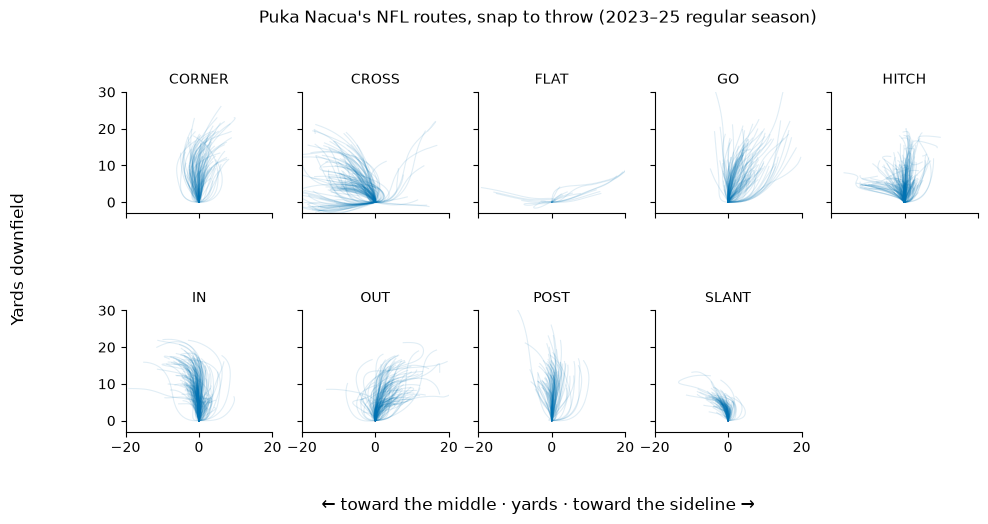

In [97]:
counts = puka_routes.route_ran.value_counts()
keep_routes = sorted(counts[counts >= 20].index) # get only routes that he ran at least 20 times

fig, axes = plt.subplots(2, 5, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, route in zip(axes.flat, keep_routes): # for each route, plot all the paths he took
    for _, path in puka_tree[puka_tree.route_ran == route].groupby(["game_id", "play_id"]):
        ax.plot(path.toward_sideline, path.downfield, color="#0072B2", alpha=0.12, lw=0.8) # alpha = transparency, lw = line width
    ax.set_title(route, fontsize=10)
    ax.set_xlim(-20, 20)
    ax.set_ylim(-3, 30)
    ax.set_aspect("equal")

for ax in axes.flat[len(keep_routes):]:
    ax.axis("off") # get rid of empty subplots
fig.supxlabel("← toward the middle · yards · toward the sideline →")
fig.supylabel("Yards downfield")
fig.suptitle("Puka Nacua's NFL routes, snap to throw (2023–25 regular season)")
plt.show()

<details>
<summary><b>What else would make sense to visualize? In general + for more information on the route tree</b></summary>

* How long each route takes to develop (speed curves i.e draw his speed against time since the snap on average for each route)
* Success rate of routes (measured through e.g separation, caught balls, etc.) (success rate panel report card per route)
* Game state (time, score) when he runs said routes (ideas?)

</details>

# Part 4: The Combine

## Combine tracking: load and tidy

We need to do some data cleaning first!!

In [98]:
d = pd.read_csv(f"{bdb_dir}/combine_tracking.csv", parse_dates=["time"])

In [99]:
# Drill names inconcistent across seasons:
# 
DRILL_ALIASES = {"LINE": "LINE_DRILL",                      
                 "PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL",
                 "OVER_THE_SHOULDER_ADJUST": "OVER_SHOULDER_ADJUST",
                 "SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT"}
ATTEMPT = ["event_id", "nfl_id", "drill_name", "attempt"]

# Get the combine tracking data, filtered to only be players (i.e no ball), 
combine_trk = (pd.read_csv(f"{bdb_dir}/combine_tracking.csv", parse_dates=["time"])
               .query("entity_type == 'PLAYER'")                # drop the ball
               .assign(drill_name=lambda d: d.drill_name.replace(DRILL_ALIASES))
               .sort_values(["nfl_id", "drill_name", "attempt", "time"]))

# Calculate the distance that each player traveled during each attempt, and the time since the start of the attempt.
by_attempt = combine_trk.groupby(ATTEMPT)
combine_trk["t"] = (combine_trk.time - by_attempt.time.transform("first")).dt.total_seconds()
combine_trk["step"] = np.hypot(by_attempt.x.diff(), by_attempt.y.diff()).fillna(0)
combine_trk["path_length"] = combine_trk.groupby(ATTEMPT).step.cumsum()  

print(combine_trk.drop_duplicates(["drill_type", "draft_year", "nfl_id"])
      .pivot_table(index="drill_type", columns="draft_year", values="nfl_id",
                   aggfunc="count", fill_value=0))


draft_year        2023  2024  2025
drill_type                        
FORTY_YARD_DASH    138   147   133
SHORT_SHUTTLE       46    61    63
SKILL_DRILLS_DB     35    50    37
SKILL_DRILLS_DL     33    37    44
SKILL_DRILLS_LB      4     0     0
SKILL_DRILLS_OL     37    46    38
SKILL_DRILLS_TE     12    13    17
SKILL_DRILLS_WR     39    31    37
THREE_CONE_DRILL    45    60    55


<details>
<summary><b>Can someone interpret this? ^</b></summary>

For each year, the number of unique participations in the drill. e.g in 2023, 138 people participated in the 40 yard dash. 

</details>

## The 40-yard dash, frame by frame

Lets look specifically at the 40 yard dash. We will derive the 40yard time, and the top speed, from the tracking data. (then compare vs the recorded data)

## What a 40 looks like

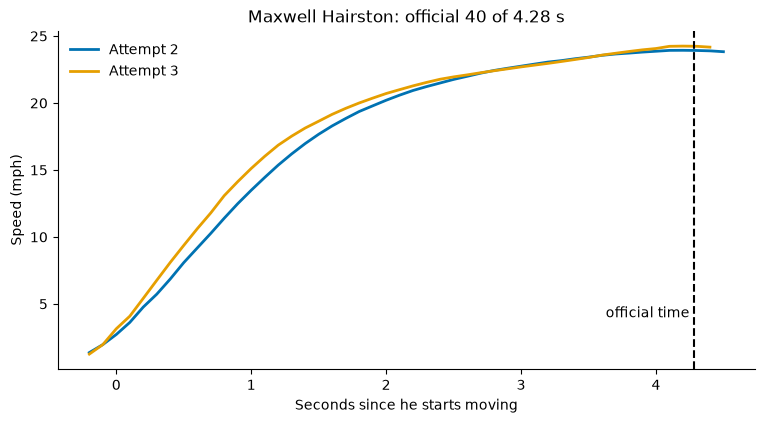

In [100]:
# fastest official 40 among players with tracked 40 attempts
dash = combine_trk[combine_trk.drill_name == "FORTY_YARD_DASH"]
fastest = (combine[combine.nfl_id.isin(dash.nfl_id)]
           .nsmallest(1, "forty").iloc[0])
fastest_id = int(fastest.nfl_id)
fastest_name = players.set_index("nfl_id").display_name[fastest_id]
MPH = 3600 / 1760                                   # yd/s -> mph
colours = ["#0072B2", "#E69F00", "#009E73"]

runs = dash[dash.nfl_id == fastest_id]
fig, ax = plt.subplots(figsize=(9, 4.4))
for (att, d), col in zip(runs.groupby("attempt"), colours):
    d = d.sort_values("t")
    t_start = d.loc[d.s > 1, "t"].min()             # clock starts once he's moving
    ax.plot(d.t - t_start, d.s * MPH, lw=2, color=col, label=f"Attempt {att}")
ax.axvline(fastest.forty, color="k", ls="--")
ax.text(fastest.forty, 4, "official time ", ha="right")
ax.set(xlabel="Seconds since he starts moving", ylabel="Speed (mph)",
       title=f"{fastest_name}: official 40 of {fastest.forty} s")
ax.legend(frameon=False)
plt.show()


## Combine routes vs. NFL routes

Lets look at one example of a player's combine routes vs how they actually play in the NFL. Obviously there are a lot of considerations at play, but you would assume that teams shouldn't just draft the best athlete, but who fits their scheme.

Normalize each Combine attempt: start at (0, 0), then rotate so that the first 3 yards of the stem point straight up.

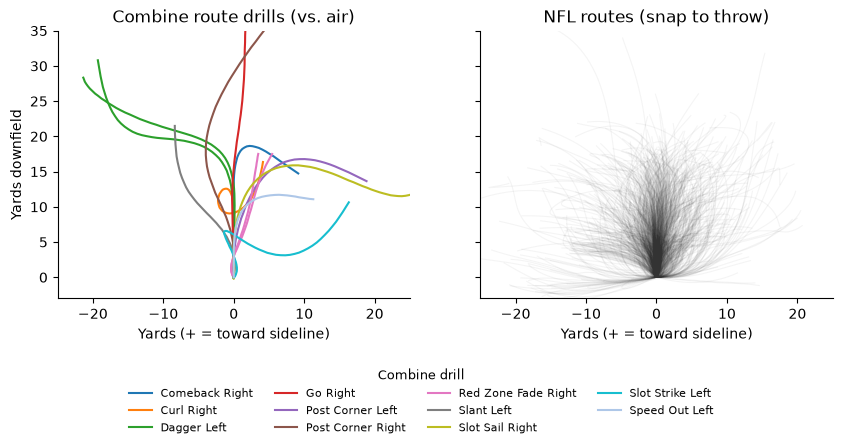

In [101]:
def normalize_attempt(d):
    d = d.sort_values("t")
    i = np.argmax(d.path_length.to_numpy() >= 3)
    dx, dy = d.x - d.x.iloc[0], d.y - d.y.iloc[0]
    theta = np.arctan2(dy.iloc[i], dx.iloc[i])
    return d.assign(downfield=dx * np.cos(theta) + dy * np.sin(theta),
                    lateral=dx * np.sin(theta) - dy * np.cos(theta))  # + = runner's right

routes_run = combine_trk[(combine_trk.nfl_id == puka_id)
                         & combine_trk.drill_name.str.contains("ROUTE|FADE")]
puka_combine = pd.concat(normalize_attempt(d) for _, d in
                         routes_run.groupby(["drill_name", "attempt", "event_id"]))
# LEFT/RIGHT in a drill name is the side he lines up on (a Slant Left breaks
# to his right), so we can put both panels on the same "toward sideline" axis
puka_combine["toward_sideline"] = np.where(puka_combine.drill_name.str.endswith("LEFT"),
                                           -puka_combine.lateral, puka_combine.lateral)

drills = sorted(puka_combine.drill_name.unique())
drill_cols = dict(zip(drills, plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2]))  # 20 distinct

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for (drill, att, _), d in puka_combine.groupby(["drill_name", "attempt", "event_id"]):
    first_att = att == puka_combine.loc[puka_combine.drill_name == drill, "attempt"].min()
    label = drill.replace("_ROUTE", "").replace("_", " ").title()
    ax1.plot(d.toward_sideline, d.downfield, lw=1.5, color=drill_cols[drill],
             label=label if first_att else None)        # one legend entry per drill
for _, d in puka_tree.groupby(["game_id", "play_id"]):
    ax2.plot(d.toward_sideline, d.downfield, color="0.2", alpha=0.05, lw=0.8)
ax1.set(title="Combine route drills (vs. air)", xlabel="Yards (+ = toward sideline)",
        ylabel="Yards downfield")
ax2.set(title="NFL routes (snap to throw)", xlabel="Yards (+ = toward sideline)")
for ax in (ax1, ax2):
    ax.set_xlim(-25, 25)
    ax.set_ylim(-3, 35)
    ax.set_aspect("equal")
fig.legend(loc="lower center", ncol=4, fontsize=8, frameon=False,
           title="Combine drill", title_fontsize=9)
fig.subplots_adjust(bottom=0.22)                       
plt.show()


LEFT/RIGHT in the drill names is the side the receiver lines up on, not the direction of the break. That was inferred from the traces, which is why you plot before you trust a label. The Combine routes are run against air and continue past the catch. The NFL routes stop at the throw.

# Part 5 · A first Combine → NFL link

## In-game top speed

The most popular drill is probably the 40yard dash. But how much does it really correlate to game performance? Does a faster receiver always perform better? You can imagine the answer is usually no, and there is lots and lots of analysis out there about 40 speeds and performance. We will instead look at a much smaller scope, of whether 40yard Combine times reflect a player's real game speed. 

Lets now look at speed during actual games --> we need to query for the regular season tracking data for speed. 

In [102]:
top_speed_file = f"{cache_dir}/game_top_speed.parquet"

# make a file for the top speeds of players in game if it doesnt exist yet 
if not os.path.exists(top_speed_file):
    speeds = tracking.to_table(
        columns=["nfl_id", "s"],
        filter=ds.field("game_id").isin(reg_game_ids.tolist())
        ).to_pandas()
    
    by_player = speeds.groupby("nfl_id").s # group by player, and get their speed values
    (pd.DataFrame({"game_top_speed": by_player.quantile(0.99),  # robust "top speed" because there are some tracking errors
                   "n_frames": by_player.size()})
     .reset_index().to_parquet(top_speed_file)) # make the parquet file
    
game_speed = pd.read_parquet(top_speed_file) 

## Join the Combine to Sundays

In [103]:
POS_GROUPS = {"WR": "WR", "TE": "TE", "RB": "RB", "FB": "RB",
              "CB": "DB", "SS": "DB", "FS": "DB", "DB": "DB",
              "OLB": "LB", "ILB": "LB", "MLB": "LB",
              "DE": "DL", "DT": "DL", "NT": "DL", "G": "OL", "T": "OL", "C": "OL"}
POS_COLS = {"WR": "#E69F00", "DB": "#56B4E9", "TE": "#009E73",
            "LB": "#CC79A7", "DL": "#D55E00", "OL": "#0072B2"}
# one row per player: top speed in any tracked 40 attempt + official 40 time
forty = (dash.groupby("nfl_id", as_index=False)
         .agg(peak_speed=("s", "max"))                                   # yd/s
         .merge(combine[["nfl_id", "forty"]].rename(columns={"forty": "official_40"}),
                on="nfl_id"))
# merge the top speed in game with the top speed in a tracked 40 attempt, and keep only players with at least 3000 frames of tracking data (5+ min
link = (forty.merge(game_speed, on="nfl_id")
        .merge(players[["nfl_id", "display_name", "nfl_position"]], on="nfl_id")
        .assign(pos_group=lambda d: d.nfl_position.map(POS_GROUPS),
                peak_speed_mph=lambda d: d.peak_speed * MPH, # convert yd/s to mph
                game_top_speed_mph=lambda d: d.game_top_speed * MPH)
        .query("n_frames >= 3000 and pos_group != 'RB'"))  # only 1 rb, exclude them for now 

print(link.pos_group.value_counts())

pos_group
DB    66
OL    64
WR    63
DL    57
TE    21
LB    16
Name: count, dtype: int64


In [110]:
link.head(5)

,nfl_id,peak_speed,official_40,game_top_speed,n_frames,display_name,nfl_position,pos_group,peak_speed_mph,game_top_speed_mph
0,55867,10.416667,4.60,6.77,133745,Will Anderson,DE,DL,21.306818,13.847727
1,55874,10.073333,5.01,5.35,237100,Darnell Wright,T,OL,20.604545,10.943182
2,55875,9.253333,5.16,5.26,214646,Peter Skoronski,G,OL,18.927273,10.759091
3,55877,10.640000,4.58,7.00,74967,Lukas Van Ness,DE,DL,21.763636,14.318182
4,55878,9.966667,4.97,5.40,175500,Broderick Jones,T,OL,20.386364,11.045455


So we end up with a dataframe of the speeds (top combine speed, official 40, top game speed) of prospects during any 40 attempt of the combine, with at least 5min+ of data. 

## Does Combine speed matter in actual games?

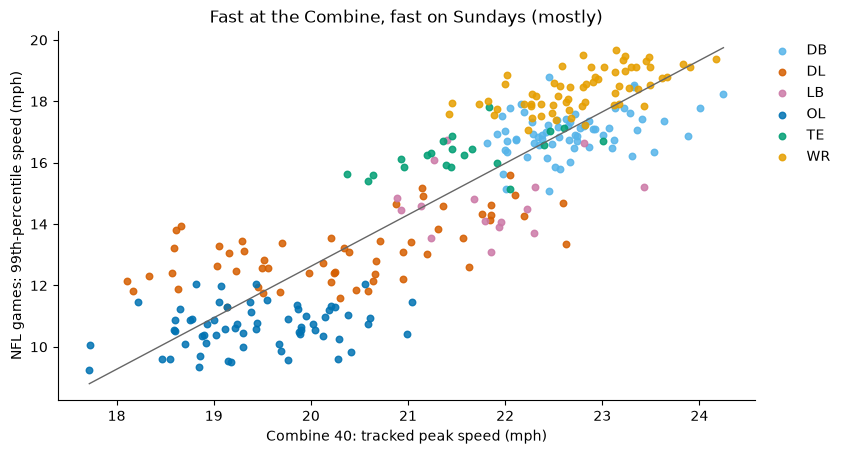

In [105]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for grp, d in link.groupby("pos_group"):
    ax.scatter(d.peak_speed_mph, d.game_top_speed_mph, s=22, alpha=0.85,
               color=POS_COLS[grp], label=grp)
slope, intercept = np.polyfit(link.peak_speed_mph, link.game_top_speed_mph, 1)
xs = np.linspace(link.peak_speed_mph.min(), link.peak_speed_mph.max(), 50)
ax.plot(xs, intercept + slope * xs, color="0.4", lw=1)
ax.set(xlabel="Combine 40: tracked peak speed (mph)",
       ylabel="NFL games: 99th-percentile speed (mph)",
       title="Fast at the Combine, fast on Sundays (mostly)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Does Combine speed matter in actual games?

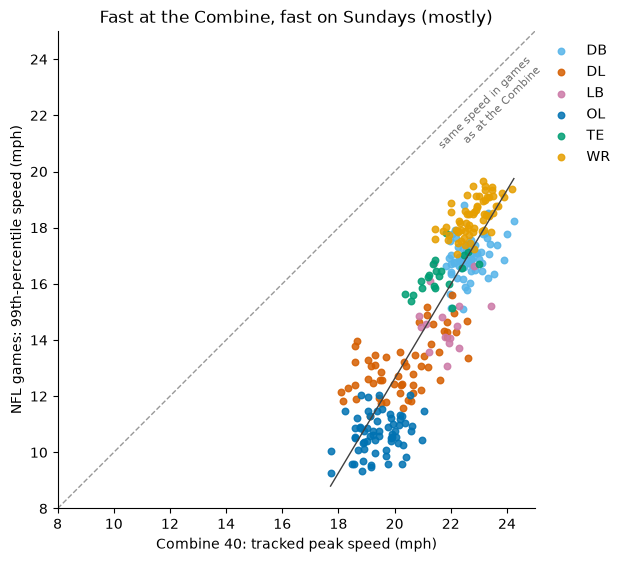

In [106]:
fig, ax = plt.subplots(figsize=(7, 6.2))
lims = (8, 25)                                        # same range on both axes
ax.plot(lims, lims, color="0.6", ls="--", lw=1)       # game speed = Combine speed
ax.text(24.6, 24.2, "same speed in games\nas at the Combine", ha="right", va="top",
        fontsize=8, color="0.45", rotation=45, rotation_mode="anchor")
for grp, d in link.groupby("pos_group"):
    ax.scatter(d.peak_speed_mph, d.game_top_speed_mph, s=22, alpha=0.85,
               color=POS_COLS[grp], label=grp)
slope, intercept = np.polyfit(link.peak_speed_mph, link.game_top_speed_mph, 1)
xs = np.linspace(link.peak_speed_mph.min(), link.peak_speed_mph.max(), 50)
ax.plot(xs, intercept + slope * xs, color="0.25", lw=1)
ax.set(xlim=lims, ylim=lims, aspect="equal",
       xlabel="Combine 40: tracked peak speed (mph)",
       ylabel="NFL games: 99th-percentile speed (mph)",
       title="Fast at the Combine, fast on Sundays (mostly)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()


## Does Combine speed matter in actual games? 

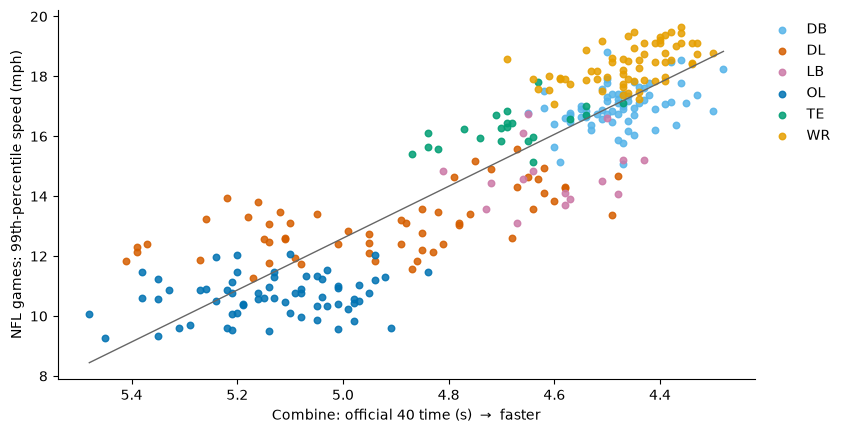

In [107]:
d40 = link.dropna(subset=["official_40"])
fig, ax = plt.subplots(figsize=(9, 4.8))
for grp, d in d40.groupby("pos_group"):
    ax.scatter(d.official_40, d.game_top_speed_mph, s=22, alpha=0.85,
               color=POS_COLS[grp], label=grp)
slope, intercept = np.polyfit(d40.official_40, d40.game_top_speed_mph, 1)
xs = np.linspace(d40.official_40.min(), d40.official_40.max(), 50)
ax.plot(xs, intercept + slope * xs, color="0.4", lw=1)
ax.invert_xaxis()                                   # faster (lower) times on the right
ax.set(xlabel="Combine: official 40 time (s)  →  faster",
       ylabel="NFL games: 99th-percentile speed (mph)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()


## Does Combine speed matter in actual games?

Why split by position?
The overall Pearson's r looks strong but is just due to positional groupings: linemen are slow at the Combine and their jobs don't ask them to sprint on Sundays, while receivers are fast at both. The pooled line is mostly connecting those clusters.

The real question is within a position: among WRs, does the faster player at the Combine actually play faster? So we compute the correlation separately for each position group, and compare two Combine measures to the game top speed:

```r_tracked_peak```: top speed from the tracking data in the 40

```r_official_40```: the official (laser) 40 time, negated so that faster = positive

In [108]:
# Correlation between tracked peak speed in combine 40 and top speed in games, and correlation between official 40 time and top speed in games (negated because lower 40 time is better)
def corrs(d):
    return pd.Series({"n": len(d),
                      "r_tracked_peak": d.peak_speed.corr(d.game_top_speed), # correlation between tracked peak speed in combine 40 and top speed in games
                      "r_official_40": (-d.official_40).corr(d.game_top_speed)}) # correlation between official 40 time and top speed in games (negated because lower 40 time is better)

print(pd.concat([link.assign(pos_group="All"), link])
      .groupby("pos_group").apply(corrs, include_groups=False)
      .round(2).astype({"n": int}).sort_values("n", ascending=False))

             n  r_tracked_peak  r_official_40
pos_group                                    
All        287            0.88           0.89
DB          66            0.35           0.37
OL          64            0.23           0.20
WR          63            0.61           0.52
DL          57            0.58           0.60
TE          21            0.55           0.59
LB          16            0.12           0.16


## So is this a submission? No!!! 

* This is just useful to get familiar with the data.
* One useful thing is looking at past projects for previous BDBs, and drawing inspiration from their a) visualizations b) formatting c) thesis
  * Make sure to properly cite them in your notebook - if anything it makes you look better

# Part 6 · Your turn

## Idea starters

| Combine signal (tracking) | NFL outcome (`player_play` + tracking) |
|---|---|
| WR route drills: break deceleration, exit burst, how alike stems look | `separation_at_pass_forward`, targets per route run |
| DB backpedal + 90° break, W drill: transition time | separation allowed (WR rows on the same play), `coverage_assignment` |
| OL mirror / wave drills: lateral quickness | `pressure_allowed`, `time_to_pressure_allowed`, `sack_allowed` |
| DL pass-rush drills: first-step burst | `player_get_off`, `time_to_pressure`, `unblocked_pressure` |
| Tracked 10-yard split vs. 40 time | in-game acceleration in the first second after the snap |
| Gauntlet: speed kept while catching | `yards_after_catch - expected_yards_after_catch` |

Pick something a scout or coach would act on: “watch for X in drill Y, because it predicts Z.”

## Tips from past entries

- **Start with a football question** and treat the metric as a means. Judges are team analytics staff.
- **Cut the data early:** regular season, non-nullified plays, the frames you need, Parquet.
- **Animate before you model.** Most bugs are visible.
- **Check reliability** (attempt-to-attempt, odd vs. even games) before you check correlation.
- **Control for the obvious:** position, draft slot, alignment, team, exposure.
- **Budget the figures:** fewer than 10, and each one should carry a claim.
- The notebook must run **top to bottom on Kaggle**, so test it there early.
- Sign up for the **BDB mentorship** program, and get a football person to read your draft.

## Resources

**Getting started with football analytics**

- Eric Eager & Richard Erickson, [*Football Analytics with Python & R*](https://www.oreilly.com/library/view/football-analytics-with/9781492099611/) (O’Reilly, 2023). The friendliest start: play-by-play data with `nflfastR` / `nfl_data_py`, EPA, regression and the draft, in both languages. It doesn’t use tracking data, so pair it with this deck.
- Bradley Congelio, [*Introduction to NFL Analytics with R*](https://bradcongelio.com/nfl-analytics-with-r-book/) (CRC, 2023; free online). Covers tidyverse wrangling, the nflverse, `ggplot2`/`gt` visualization and `tidymodels`.
- C. B. Zakarian, [nflanalytic.com tutorials](https://nflanalytic.com/tutorials.html). 40+ chapters from EPA to win probability; Ch. 34 covers tracking data.

**Tracking data and the Big Data Bowl**

- Ron Yurko, [CMSAC 2022 BDB workshop](https://www.stat.cmu.edu/cmsac/conference/2022/workshop/slides.html). This deck’s starting point, plus a full sack-probability model with cross-validation.
- Ben Baldwin, [ngscleanR](https://github.com/guga31bb/ngscleanR). The cleaning helpers we rebuilt here.
- [BDB 2027 on Kaggle](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027): the data dictionary, rules, public notebooks and discussion forum.
- [Past Big Data Bowl winners](https://operations.nfl.com/gameday/analytics/big-data-bowl/). Read a few winning writeups before you write yours.

**Some articles to read for this year's BDB**

- [NFL Combine Scores Explained (RAS)](https://athletecalculator.com/nfl-combine-scores-explained)
- [Analysis of Combine Drills' Effect on Draft Position](https://www.unexpectedpoints.com/p/scouting-combine-drills-that-matter-0a8)
- [Berkeley SPAN](https://sportsanalytics.studentorg.berkeley.edu/articles/nfl-combine.html)


## Appendix: the helper functions

| Function | ngscleanR analogue | What it does |
|---|---|---|
| `find_bdb_dir()` | – | finds the data locally or on Kaggle |
| `add_frame_id()` | – | 10 Hz frame numbers from `time` |
| `standardize_tracking()` | `clean_and_rotate()` | offense moves right; flips `x`, `y`, `dir`, `o`; adds `dir_x/y`, `s_x/y` |
| `add_los()` | (part of `prepare_bdb_week()`) | line of scrimmage `los_x`, `x_from_los` |
| `trim_plays()` | `cut_plays()` | keeps snap → end-event frames; adds `frames_since_snap` |
| `geom_field()` / `draw_field()` | – | a field background |
| `plot_play()` | `plot_play()` | one frame with trails and direction arrows |
| `normalize_attempt()` | – | Combine attempt → start at origin, stem pointing up |

All the code is in `bdb_tutorial.R` and `bdb_tutorial.py`, generated from this deck by `extract_code.R`.